# Лабораторная работа № 1
## Обучение полносвязных нейронных сетей: регрессия
### Вариант 7

Набор данных: Wine Quality, файл `winequality-white.csv`. Целевой признак `quality` - оценка качества белого вина.

## Цель работы

Получить практические навыки подготовки табличных данных, построения, обучения и оценки полносвязных нейронных сетей прямого распространения (MLP) для задачи регрессии.

## Задание

1. Загрузить и исследовать набор данных: типы признаков, пропуски, дубликаты, выбросы, статистика целевого признака.
2. Исключить признаки с утечкой, разделить данные на обучающую, валидационную и тестовую части (70 / 15 / 15).
3. Обучить предобработку только на обучающей части.
4. Разработать не менее трех архитектур MLP, исследовать влияние числа слоев, числа нейронов, функции активации, оптимизатора и параметров обучения.
5. Посчитать MSE, MAE и R2, сравнить модели с базовой моделью `Dummy`, проверить наличие переобучения.
6. Выбрать лучшую модель по валидационной выборке и один раз оценить ее на тестовой.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras нужно выбрать до импорта keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты и константы эксперимента. Все настройки собраны здесь, чтобы условия обучения были одинаковыми для всех моделей.

In [2]:
import json
import time

import joblib
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA_FILE = DATA_DIR / "wine-quality" / "winequality-white.csv"

TARGET = "quality"

# Общие условия обучения
MAX_EPOCHS = 300
BATCH_SIZE = 64
LEARNING_RATE = 0.001
PATIENCE = 20

# Если модели отличаются по MSE меньше этого значения, разницу считаем шумом
# и оставляем более простую модель: сложность должна окупаться качеством.
MSE_TOLERANCE = 0.002

# Цвета кривых, одинаковые на всех графиках работы
TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEST_COLOR = "#52514e"

## Описание набора данных

**Источник:** [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), UCI Machine Learning Repository. Файл: `winequality-white.csv`, разделитель `;`.

Ссылка на первоисточник: P. Cortez, A. Cerdeira, F. Almeida, T. Matos, J. Reis. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, Elsevier, 47(4):547-553, 2009.

**Перевод описания набора:**

Два набора данных относятся к красному и белому вариантам португальского вина Vinho Verde. Из соображений конфиденциальности и логистики доступны только физико-химические (входные) и сенсорные (выходной) показатели: нет данных о сорте винограда, марке вина, цене продажи. Выходное значение основано на сенсорных данных: это медиана как минимум трех оценок экспертов. Каждый эксперт оценивал вино от 0 (очень плохое) до 10 (превосходное).

Наборы можно рассматривать как задачу классификации или регрессии. Классы упорядочены и не сбалансированы: нормальных вин гораздо больше, чем отличных или плохих. Авторы также не уверены, что все входные признаки важны, поэтому может быть интересен отбор признаков. Некоторые признаки могут коррелировать. Пропущенных значений нет. Белых вин 4898.

**Поля набора:**

| Поле | Содержание | Единицы |
|---|---|---|
| `fixed acidity` | Нелетучая кислотность | г/дм3 винной кислоты |
| `volatile acidity` | Летучая кислотность | г/дм3 уксусной кислоты |
| `citric acid` | Лимонная кислота | г/дм3 |
| `residual sugar` | Остаточный сахар | г/дм3 |
| `chlorides` | Хлориды | г/дм3 хлорида натрия |
| `free sulfur dioxide` | Свободный диоксид серы | мг/дм3 |
| `total sulfur dioxide` | Общий диоксид серы | мг/дм3 |
| `density` | Плотность | г/см3 |
| `pH` | Кислотность по шкале pH | - |
| `sulphates` | Сульфаты | г/дм3 сульфата калия |
| `alcohol` | Содержание спирта | % об. |
| `quality` | Целевой признак: оценка качества | баллы от 0 до 10 |

Загружаем файл. Если данных нет, ноутбук сразу сообщает, что и откуда скачать.

In [3]:
# labs/data нет в git, поэтому каждый участник скачивает набор сам
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Не найден файл {DATA_FILE}. Скачайте набор https://archive.ics.uci.edu/dataset/186/wine+quality "
        "и положите winequality-white.csv в папку labs/data/wine-quality"
    )

# В этом файле столбцы разделены точкой с запятой
raw_data = pd.read_csv(DATA_FILE, sep=";", encoding="utf-8")
print("Размер набора (записей, столбцов):", raw_data.shape)
raw_data.head(10)

Размер набора (записей, столбцов): (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


## Анализ данных

### Типы полей и описательная статистика

In [4]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [5]:
raw_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.0,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.550,1.080


In [6]:
print("Пропусков всего:", raw_data.isna().sum().sum())
duplicate_count = raw_data.duplicated().sum()
print("Полных дубликатов:", duplicate_count, f"({duplicate_count / len(raw_data):.2%})")
print("Записей после их удаления:", len(raw_data) - duplicate_count)

Пропусков всего: 0
Полных дубликатов: 937 (19.13%)
Записей после их удаления: 3961


**Результат:** 4898 записей, 12 числовых столбцов: 11 признаков типа float и целый `quality`. Строковых полей и пропусков нет. Полных дубликатов 937 (19,13%), это много: после их удаления останется 3961 запись.

### Целевой признак

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5

Среднее: 5.8779  Отклонение: 0.8856


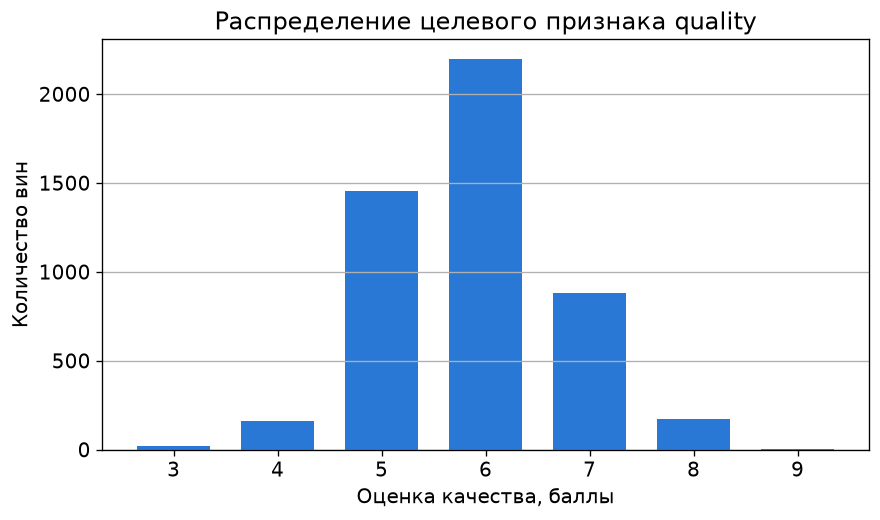

In [7]:
target_counts = raw_data[TARGET].value_counts().sort_index()
print(target_counts.to_string())
print("\nСреднее:", round(raw_data[TARGET].mean(), 4), " Отклонение:", round(raw_data[TARGET].std(), 4))

figure, axis = plt.subplots(figsize=(7.5, 4.5))
axis.bar(target_counts.index.astype(str), target_counts.values, color=TRAIN_COLOR, width=0.7)
axis.set_xlabel("Оценка качества, баллы")
axis.set_ylabel("Количество вин")
axis.set_title("Распределение целевого признака quality")
axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "regression-target.png")
plt.show()

**Результат:** оценки встречаются от 3 до 9, но сосредоточены на 5-7: 1457, 2198 и 880 вин. Оценок 3 и 9 только 20 и 5. Среднее 5,8779, отклонение 0,8856. Распределение почти нормальное с редкими краями, поэтому модели будет трудно предсказывать крайние оценки.

### Выбросы

Проверяем признаки правилом 1,5 межквартильного размаха и диаграммами размаха.

,Признак,Нижняя граница,Верхняя граница,Записей вне границ,Минимум,Максимум
0,fixed acidity,4.8000,8.8000,119,3.80000,14.20000
1,volatile acidity,0.0450,0.4850,186,0.08000,1.10000
2,citric acid,0.0900,0.5700,270,0.00000,1.66000
3,residual sugar,-10.6000,22.2000,7,0.60000,65.80000
4,chlorides,0.0150,0.0710,208,0.00900,0.34600
5,free sulfur dioxide,-11.5000,80.5000,50,2.00000,289.00000
6,total sulfur dioxide,19.5000,255.5000,19,9.00000,440.00000
7,density,0.9852,1.0027,5,0.98711,1.03898
8,pH,2.8050,3.5650,75,2.72000,3.82000
9,sulphates,0.2000,0.7600,124,0.22000,1.08000


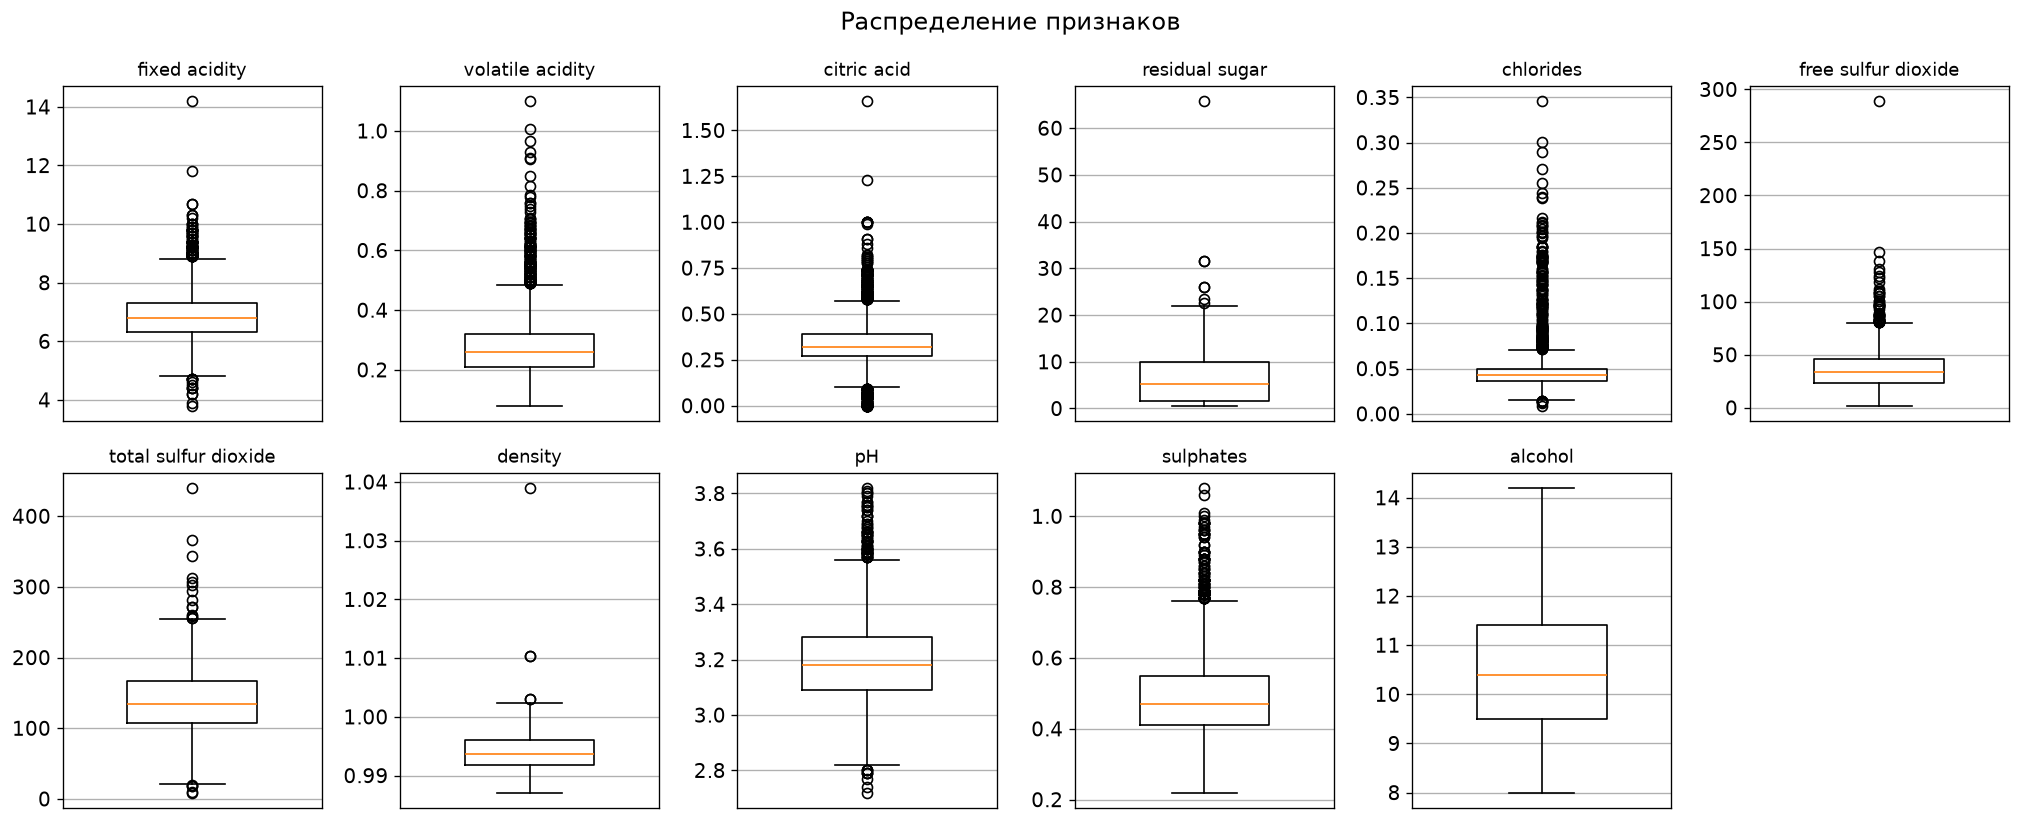

In [8]:
feature_columns = [column for column in raw_data.columns if column != TARGET]

outlier_rows = []
for column in feature_columns:
    first_quartile, third_quartile = raw_data[column].quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    lower_bound = first_quartile - 1.5 * iqr
    upper_bound = third_quartile + 1.5 * iqr
    outside_count = int(((raw_data[column] < lower_bound) | (raw_data[column] > upper_bound)).sum())
    outlier_rows.append({"Признак": column, "Нижняя граница": round(lower_bound, 4),
                         "Верхняя граница": round(upper_bound, 4), "Записей вне границ": outside_count,
                         "Минимум": raw_data[column].min(), "Максимум": raw_data[column].max()})
display(pd.DataFrame(outlier_rows))

figure, axes = plt.subplots(2, 6, figsize=(17, 7))
for axis, column in zip(axes.ravel(), feature_columns):
    axis.boxplot(raw_data[column], widths=0.5)
    axis.set_title(column, fontsize=11)
    axis.set_xticks([])
axes.ravel()[-1].set_visible(False)
figure.suptitle("Распределение признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "regression-outliers.png")
plt.show()

**Результат:** больше всего значений вне границ у `citric acid` (270), `chlorides` (208), `volatile acidity` (186). Значения лежат в возможных пределах, а редкие высокие показатели, например `residual sugar` 65,8, - это реальные особенности вин, а не ошибки ввода. Поэтому записи не удаляем.

### Матрица корреляций

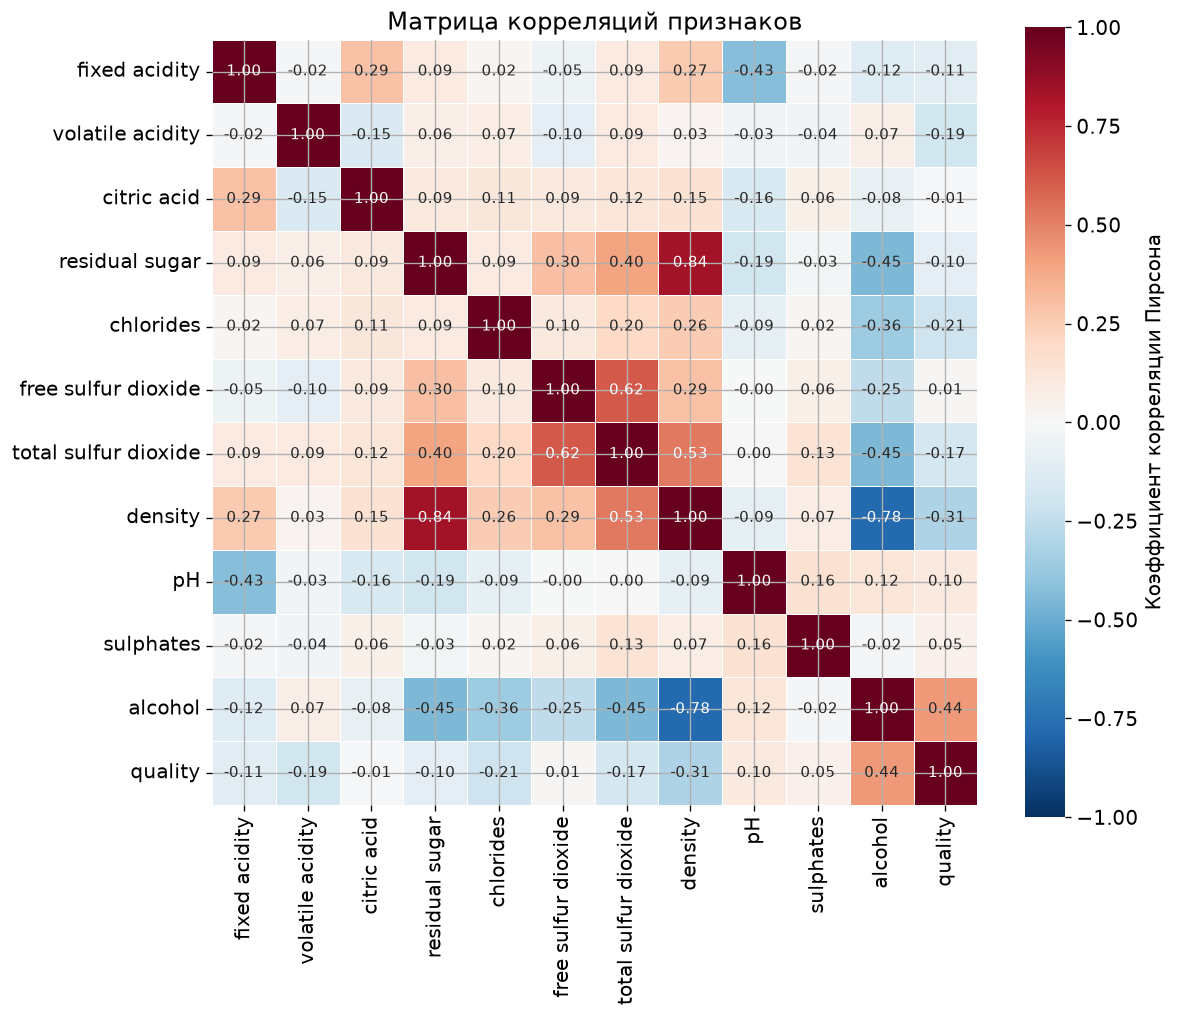

alcohol                 0.436
density                -0.307
chlorides              -0.210
volatile acidity       -0.195
total sulfur dioxide   -0.175
fixed acidity          -0.114
pH                      0.099
residual sugar         -0.098
sulphates               0.054
citric acid            -0.009
free sulfur dioxide     0.008


In [9]:
correlation_matrix = raw_data.corr()

figure, axis = plt.subplots(figsize=(10, 8.5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 9},
            cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "regression-correlation.png")
plt.show()

print(correlation_matrix[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).round(3).to_string())

**Результат:** сильнее всего с `quality` связаны `alcohol` (0,436) и `density` (-0,307), далее `chlorides` (-0,210), `volatile acidity` (-0,195). Подозрительно высокой корреляции с целью нет, поэтому явной утечки нет. Но и сильной линейной связи нет: только один признак объясняет заметную часть дисперсии. Сама оценка основана на вкусе и не полностью определяется этими показателями.

## Подготовка данных

### Удаление дубликатов и отбор признаков

Совпадение всех 11 непрерывных измерений случайно почти невозможно, поэтому полные дубликаты - это повторы одной и той же записи. Если их оставить, одно и то же вино окажется в обучающей и в тестовой части, и метрики будут завышены. Удаляем их до разбиения: это единственный шаг, который выполняется раньше разбиения.

Идентификаторов в наборе нет, все 11 признаков - лабораторные измерения, полученные независимо от дегустации, поэтому утечки цели нет. `density` сильно связан с `residual sugar`, но для нейронной сети корреляция признаков не ошибка, поэтому оставляем оба.

In [10]:
data = raw_data.drop_duplicates().reset_index(drop=True)
print("Записей после удаления дубликатов:", len(data))

Записей после удаления дубликатов: 3961


### Разбиение на выборки

Разбиваем в два шага 70 / 15 / 15, `random_state=SEED`. Стратификация не нужна: это регрессия. Этот же код используется в лабораторной работе 5.

In [11]:
X_full = data[feature_columns]
y_full = data[TARGET].to_numpy(dtype="float32")

# Первый шаг: 70% обучающая часть, 30% временный остаток
X_train_raw, X_rest_raw, y_train, y_rest = train_test_split(
    X_full, y_full, test_size=0.30, random_state=SEED
)
# Второй шаг: остаток делим пополам на валидационную и тестовую части
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_rest_raw, y_rest, test_size=0.50, random_state=SEED
)

split_summary = pd.DataFrame({
    "Записей": [len(y_train), len(y_val), len(y_test)],
    "Среднее quality": [round(float(y.mean()), 4) for y in (y_train, y_val, y_test)],
    "Отклонение quality": [round(float(y.std()), 4) for y in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
split_summary.to_csv(RESULTS_DIR / "regression-split.csv", encoding="utf-8")
split_summary

,Записей,Среднее quality,Отклонение quality
train,2772,5.8615,0.8914
validation,594,5.7862,0.8875
test,595,5.8924,0.8860


**Результат:** train 2772, validation 594, test 595 записей. Среднее и отклонение `quality` в частях близки (5,8615, 5,7862, 5,8924), значит случайное разбиение дало сопоставимые выборки. Набор не сокращался, кроме удаления дубликатов.

### Предобработка

- Пропусков нет, импутация не нужна. Строковых полей нет.
- Выбросы: значения вне правила 1,5 IQR - редкие, но возможные измерения реальных вин. Обрезать и удалять их не будем. Смягчаем их влияние масштабированием, а чувствительность оценки к ним проверяем через MAE.
- Все признаки приводим к нулевому среднему и единичному отклонению (`StandardScaler`), параметры считаем только на обучающей части.
- Целевой признак не масштабируем: MSE и MAE сразу выражаются в баллах качества, и обратное преобразование не требуется.

In [12]:
# fit только на train, к остальным частям применяем transform
preprocessor = StandardScaler()
X_train = preprocessor.fit_transform(X_train_raw).astype("float32")
X_val = preprocessor.transform(X_val_raw).astype("float32")
X_test = preprocessor.transform(X_test_raw).astype("float32")

# Предобработка нужна лабораторной работе 5, поэтому сохраняем ее рядом с моделями
joblib.dump(preprocessor, MODELS_DIR / "regression-preprocessor.joblib")

print("Размеры матриц:", X_train.shape, X_val.shape, X_test.shape)
print("Среднее на train:", X_train.mean(axis=0).round(3))
print("Отклонение на train:", X_train.std(axis=0).round(3))

Размеры матриц: (2772, 11) (594, 11) (595, 11)
Среднее на train: [ 0.  0.  0. -0. -0.  0. -0.  0. -0.  0.  0.]
Отклонение на train: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Базовая модель

Метрики задания считаются одной функцией для всех моделей:

$$ MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2, \quad MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|, \quad R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2} $$

`Dummy` всегда предсказывает среднее значение `quality` обучающей части. Для нее R2 близок к 0.

In [13]:
def evaluate_regression(y_true, predictions):
    """Считает метрики задания. Цель не масштабировалась, поэтому MSE и MAE в баллах."""
    return {
        "MSE": round(float(mean_squared_error(y_true, predictions)), 4),
        "MAE": round(float(mean_absolute_error(y_true, predictions)), 4),
        "R2": round(float(r2_score(y_true, predictions)), 4),
    }


# Dummy обучается на той же обучающей части, что и нейронные сети
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
print("Прогноз Dummy (среднее train):", round(float(dummy_model.constant_[0, 0]), 4))
print("Dummy на validation:", evaluate_regression(y_val, dummy_model.predict(X_val)))

Прогноз Dummy (среднее train): 5.8615
Dummy на validation: {'MSE': 0.7933, 'MAE': 0.6865, 'R2': -0.0072}


**Результат:** `Dummy` всегда выдает 5,8615. На validation MSE 0,7933, MAE 0,6865, R2 -0,0072. R2 чуть меньше нуля, потому что среднее считалось по train, а не по validation. Это нижняя планка для всех сетей.

## Эксперименты

Все модели обучаются при одинаковых условиях, если эксперимент не меняет именно этот параметр:

- функция потерь: MSE, выходной слой: один нейрон без активации (линейный выход);
- оптимизатор Adam, скорость обучения 0,001, размер пакета 64;
- не более 300 эпох, Early Stopping по `val_loss` с терпением 20 эпох и восстановлением лучших весов.

Сравнение идет только по validation. Главный критерий - MSE (именно его минимизирует обучение). Если выигрыш меньше 0,002, оставляем более простую модель.

In [14]:
def build_mlp(hidden_units, activation="relu", optimizer_name="adam", learning_rate=LEARNING_RATE,
              dropout_rate=0.0, l2_factor=0.0):
    """Собирает и компилирует MLP для регрессии.

    hidden_units - список с числом нейронов в скрытых слоях.
    dropout_rate - доля отключаемых нейронов, 0 означает слой Dropout не добавлять.
    l2_factor - коэффициент L2-регуляризации весов, 0 означает без нее.
    """
    # Сид ставим перед каждой моделью: начальные веса не зависят от порядка экспериментов
    keras.utils.set_random_seed(SEED)

    regularizer = keras.regularizers.L2(l2_factor) if l2_factor > 0 else None

    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(X_train.shape[1],)))
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation=activation, kernel_regularizer=regularizer))
        if dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))
    # Линейный выход: прогноз не ограничен диапазоном
    model.add(keras.layers.Dense(1))

    # SGD идет с моментом: без него он слишком медленный для сравнения
    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate)
    elif optimizer_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: {optimizer_name}")

    # MSE считаем отдельной метрикой: при L2-регуляризации функция потерь равна MSE плюс штраф
    # за большие веса, поэтому значение loss нельзя подписывать как MSE
    model.compile(optimizer=optimizer, loss="mse",
                  metrics=[keras.metrics.MeanSquaredError(name="mse"), "mae"])
    return model


# Здесь накапливаются результаты всех экспериментов
trained_models = {}
trained_histories = {}
model_configs = {}
experiment_rows = []


def run_experiment(model_name, hidden_units, activation="relu", optimizer_name="adam",
                   learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, dropout_rate=0.0, l2_factor=0.0,
                   max_epochs=MAX_EPOCHS, use_early_stopping=True):
    """Обучает одну модель, сохраняет ее историю и добавляет строку в таблицу экспериментов."""
    model = build_mlp(hidden_units, activation, optimizer_name, learning_rate, dropout_rate, l2_factor)

    callbacks = []
    if use_early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True))

    start_time = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                        batch_size=batch_size, callbacks=callbacks, verbose=0)
    training_seconds = time.perf_counter() - start_time

    # С ранней остановкой веса взяты с лучшей эпохи, без нее - с последней
    epochs_done = len(history.history["loss"])
    used_epoch = int(np.argmin(history.history["val_loss"])) if use_early_stopping else epochs_done - 1

    val_predictions = model.predict(X_val, batch_size=4096, verbose=0).ravel()
    train_predictions = model.predict(X_train, batch_size=4096, verbose=0).ravel()
    val_metrics = evaluate_regression(y_val, val_predictions)

    trained_models[model_name] = model
    trained_histories[model_name] = history.history
    model_configs[model_name] = {
        "hidden_units": hidden_units, "activation": activation, "optimizer_name": optimizer_name,
        "learning_rate": learning_rate, "batch_size": batch_size, "dropout_rate": dropout_rate,
        "l2_factor": l2_factor,
    }
    experiment_rows.append({
        "Модель": model_name,
        "Скрытые слои": "-".join(str(units) for units in hidden_units),
        "Активация": activation,
        "Оптимизатор": optimizer_name,
        "lr": learning_rate,
        "batch_size": batch_size,
        "Dropout": dropout_rate,
        "L2": l2_factor,
        "Параметров": model.count_params(),
        "Эпох": epochs_done,
        "Лучшая эпоха": used_epoch + 1,
        "Секунд": round(training_seconds, 1),
        "train MSE": round(float(mean_squared_error(y_train, train_predictions)), 4),
        **val_metrics,
    })
    print(f"{model_name}: эпох {epochs_done}, лучшая {used_epoch + 1}, {training_seconds:.0f} с, {val_metrics}")
    return model


def experiments_table(model_names=None):
    """Возвращает таблицу экспериментов, целиком или для перечисленных моделей."""
    table = pd.DataFrame(experiment_rows)
    if model_names is not None:
        table = table.set_index("Модель").loc[model_names].reset_index()
    return table


def select_simplest_best(candidate_names):
    """Выбирает модель по MSE на validation.

    Модели в пределах MSE_TOLERANCE от лучшей считаются равными. Среди них берем модель
    с наименьшим числом параметров, а при равенстве - стоящую в списке первой.
    """
    table = experiments_table(candidate_names).set_index("Модель")
    close_models = table[table["MSE"] <= table["MSE"].min() + MSE_TOLERANCE]
    return close_models["Параметров"].idxmin()


def plot_history(model_name, file_name, test_values=None):
    """Строит кривые MSE и MAE: train и validation на одном графике.

    test_values - словарь с итоговыми значениями на test, рисуются пунктирной линией.
    Для обычных экспериментов его нет: тестовая выборка при подборе не используется.
    Первые эпохи пропускаем: начальная ошибка на порядок больше и сжала бы весь график.
    """
    history = trained_histories[model_name]
    skipped_epochs = min(3, len(history["loss"]) - 1)
    epochs = np.arange(skipped_epochs + 1, len(history["loss"]) + 1)
    panels = [("mse", "MSE, баллы в квадрате"), ("mae", "MAE, баллы")]

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for axis, (metric, label) in zip(axes, panels):
        axis.plot(epochs, history[metric][skipped_epochs:], color=TRAIN_COLOR, linewidth=2, label="train")
        axis.plot(epochs, history[f"val_{metric}"][skipped_epochs:], color=VAL_COLOR, linewidth=2, label="validation")
        if test_values is not None:
            axis.axhline(test_values[metric], color=TEST_COLOR, linestyle="--", linewidth=2,
                         label=f"test: {test_values[metric]:.4f}")
        axis.set_xlabel("Эпоха")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.set_ylabel(label)
        axis.legend()
    figure.suptitle(f"Обучение модели {model_name}")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()

### 1. MLP-1: простейшая сеть

Начинаем с самой простой сети: один скрытый слой из 16 нейронов, ReLU. Dropout не ставим: пока нет признаков переобучения, бороться не с чем.

MLP-1: эпох 199, лучшая 179, 126 с, {'MSE': 0.5497, 'MAE': 0.5884, 'R2': 0.302}


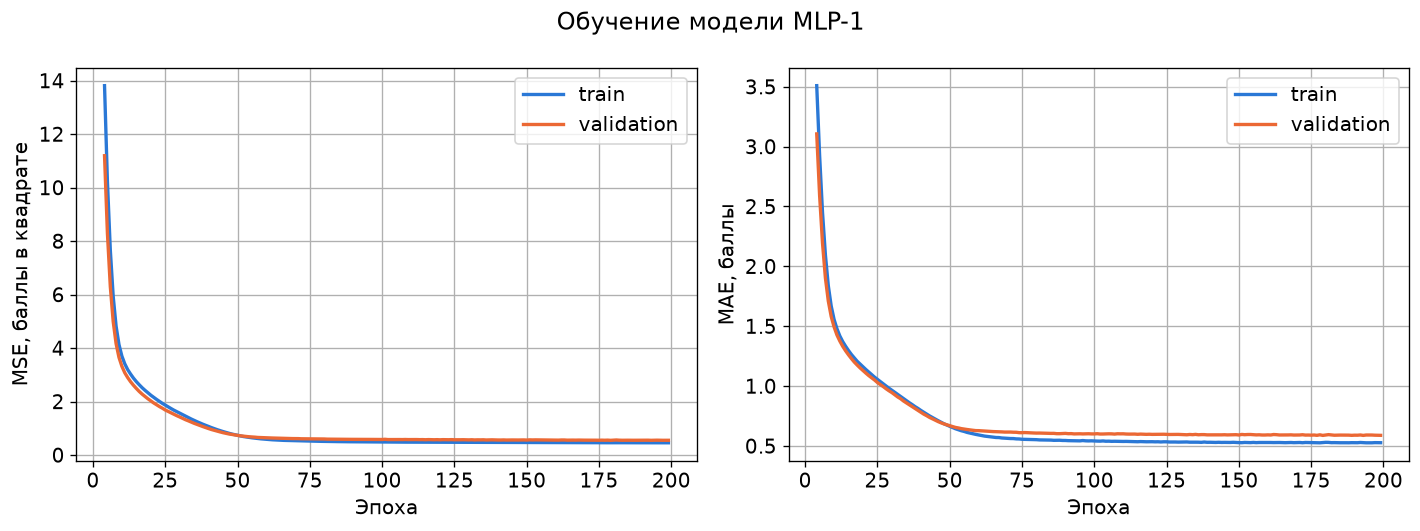

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-1,16,relu,adam,0.001,64,0.0,0.0,209,199,179,125.5,0.457,0.5497,0.5884,0.302


In [15]:
run_experiment("MLP-1", hidden_units=[16])
plot_history("MLP-1", "regression-mlp-1-history.png")
experiments_table(["MLP-1"])

**Результат:** MLP-1 (209 параметров) на validation: MSE 0,5497, MAE 0,5884, R2 0,3020. Обучение шло 199 эпох, лучшая эпоха 179: сеть учится медленно. Train MSE 0,4570 ниже validation, но разрыв небольшой. Модель уже намного лучше `Dummy`.

### 2. MLP-2: средняя сеть

Два скрытых слоя (64 и 32 нейрона). Проверяем, улучшает ли качество возможность выразить взаимодействие признаков.

MLP-2: эпох 83, лучшая 63, 52 с, {'MSE': 0.5315, 'MAE': 0.5628, 'R2': 0.3252}


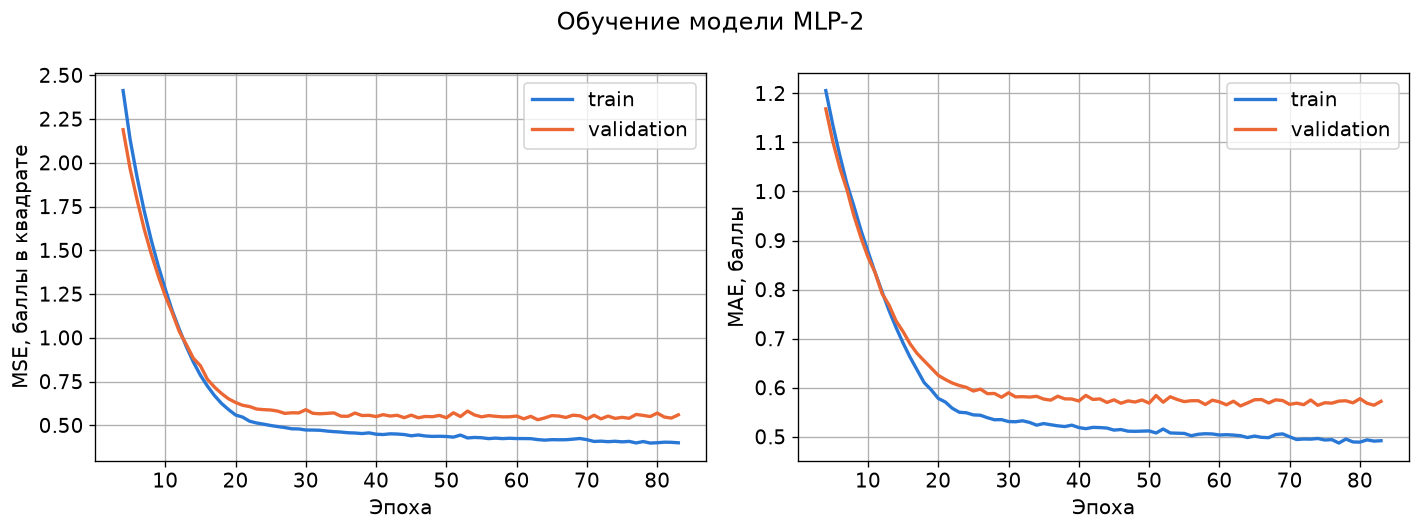

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-1,16,relu,adam,0.001,64,0.0,0.0,209,199,179,125.5,0.457,0.5497,0.5884,0.3020
1,MLP-2,64-32,relu,adam,0.001,64,0.0,0.0,2881,83,63,51.8,0.407,0.5315,0.5628,0.3252


In [16]:
run_experiment("MLP-2", hidden_units=[64, 32])
plot_history("MLP-2", "regression-mlp-2-history.png")
experiments_table(["MLP-1", "MLP-2"])

**Результат:** MLP-2 (2881 параметр): MSE 0,5315, MAE 0,5628, R2 0,3252. Прирост заметный, обучение быстрее (лучшая эпоха 63). Train MSE 0,4070, разрыв с validation вырос.

### 3. MLP-3: глубокая и широкая сеть

Три скрытых слоя (256, 128 и 64 нейрона). Обучающих записей меньше 3000, поэтому у этой модели параметров больше, чем записей: ожидаем переобучение.

MLP-3: эпох 45, лучшая 25, 31 с, {'MSE': 0.5225, 'MAE': 0.5604, 'R2': 0.3366}


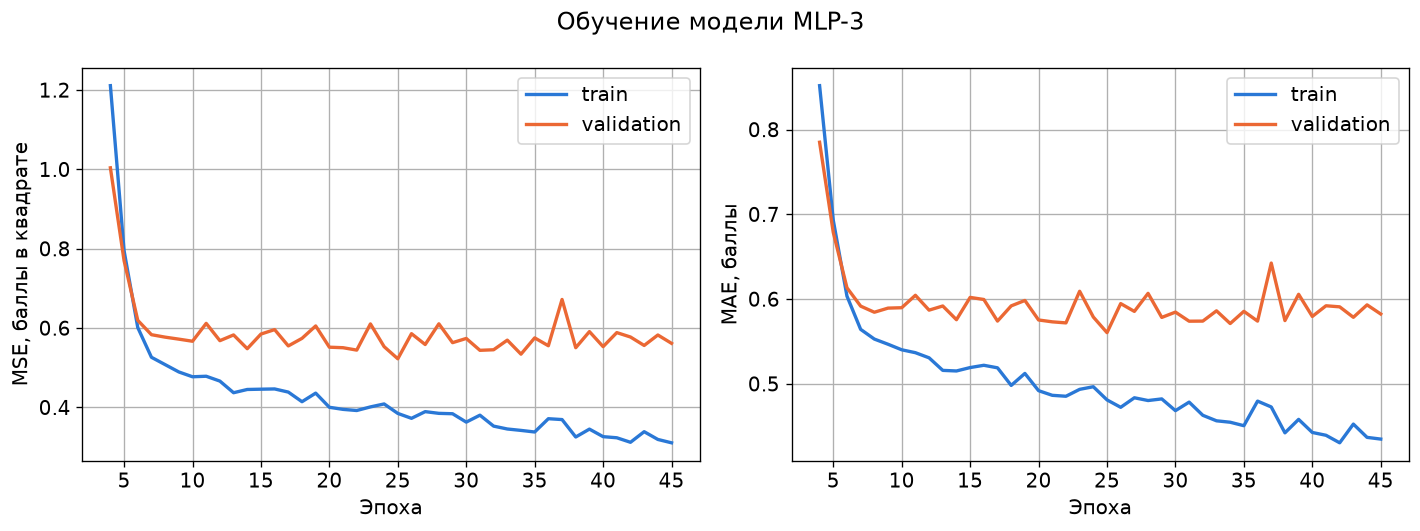

Выбрана архитектура: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-1,16,relu,adam,0.001,64,0.0,0.0,209,199,179,125.5,0.4570,0.5497,0.5884,0.3020
1,MLP-2,64-32,relu,adam,0.001,64,0.0,0.0,2881,83,63,51.8,0.4070,0.5315,0.5628,0.3252
2,MLP-3,256-128-64,relu,adam,0.001,64,0.0,0.0,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366


In [17]:
run_experiment("MLP-3", hidden_units=[256, 128, 64])
plot_history("MLP-3", "regression-mlp-3-history.png")

# Лучшая архитектура определяется автоматически по validation
architecture_names = ["MLP-1", "MLP-2", "MLP-3"]
current_name = select_simplest_best(architecture_names)
current_config = dict(model_configs[current_name])
print("Выбрана архитектура:", current_name)
experiments_table(architecture_names)

**Результат:** MLP-3 (44 289 параметров): MSE 0,5225, MAE 0,5604, R2 0,3366, лучшая эпоха 25, ранняя остановка на 45-й. Это лучшая архитектура: выигрыш 0,009 больше порога шума 0,002. Но train MSE 0,3494 намного ниже validation: параметров в 16 раз больше, чем записей, и модель начинает запоминать данные.

### 4. Функция активации

Сравниваем ReLU с tanh на выбранной архитектуре.

In [18]:
tanh_name = f"{current_name}-tanh"
run_experiment(tanh_name, **{**current_config, "activation": "tanh"})

activation_names = [current_name, tanh_name]
current_name = select_simplest_best(activation_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(activation_names)

MLP-3-tanh: эпох 64, лучшая 44, 44 с, {'MSE': 0.53, 'MAE': 0.5707, 'R2': 0.3271}
Оставляем: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-3,256-128-64,relu,adam,0.001,64,0.0,0.0,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
1,MLP-3-tanh,256-128-64,tanh,adam,0.001,64,0.0,0.0,44289,64,44,43.7,0.4133,0.5300,0.5707,0.3271


**Результат:** tanh дает MSE 0,5300 против 0,5225 у ReLU и обучается дольше (64 эпохи против 45). Оставляем ReLU.

### 5. Оптимизатор

Сравниваем Adam с RMSprop и с SGD с моментом 0,9. Скорость обучения SGD равна 0,01, чтобы он успевал сойтись.

In [19]:
rmsprop_name = f"{current_name}-rmsprop"
sgd_name = f"{current_name}-sgd"
run_experiment(rmsprop_name, **{**current_config, "optimizer_name": "rmsprop"})
run_experiment(sgd_name, **{**current_config, "optimizer_name": "sgd", "learning_rate": 0.01})

optimizer_names = [current_name, rmsprop_name, sgd_name]
current_name = select_simplest_best(optimizer_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(optimizer_names)

MLP-3-rmsprop: эпох 59, лучшая 39, 44 с, {'MSE': 0.5612, 'MAE': 0.5871, 'R2': 0.2875}


MLP-3-sgd: эпох 30, лучшая 10, 27 с, {'MSE': 0.5354, 'MAE': 0.5767, 'R2': 0.3203}
Оставляем: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-3,256-128-64,relu,adam,0.001,64,0.0,0.0,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
1,MLP-3-rmsprop,256-128-64,relu,rmsprop,0.001,64,0.0,0.0,44289,59,39,44.4,0.2920,0.5612,0.5871,0.2875
2,MLP-3-sgd,256-128-64,relu,sgd,0.010,64,0.0,0.0,44289,30,10,27.4,0.4197,0.5354,0.5767,0.3203


**Результат:** Adam 0,5225, RMSprop 0,5612, SGD с моментом 0,5354. Лучшим остается Adam. У RMSprop самый низкий train MSE (0,2920) при самой высокой ошибке на validation: он сильнее переобучается.

### 6. Скорость обучения и размер пакета

Слишком большой шаг мешает сойтись к минимуму, слишком маленький не успевает дойти до него. Размер пакета меняет число обновлений весов за эпоху и шум градиента.

In [20]:
lr_high_name = f"{current_name}-lr0.01"
lr_low_name = f"{current_name}-lr0.0001"
batch_small_name = f"{current_name}-batch32"
batch_large_name = f"{current_name}-batch256"
run_experiment(lr_high_name, **{**current_config, "learning_rate": 0.01})
run_experiment(lr_low_name, **{**current_config, "learning_rate": 0.0001})
run_experiment(batch_small_name, **{**current_config, "batch_size": 32})
run_experiment(batch_large_name, **{**current_config, "batch_size": 256})

training_names = [current_name, lr_high_name, lr_low_name, batch_small_name, batch_large_name]
current_name = select_simplest_best(training_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(training_names)

MLP-3-lr0.01: эпох 52, лучшая 32, 40 с, {'MSE': 0.5363, 'MAE': 0.5743, 'R2': 0.3191}


MLP-3-lr0.0001: эпох 117, лучшая 97, 85 с, {'MSE': 0.5297, 'MAE': 0.5701, 'R2': 0.3274}


MLP-3-batch32: эпох 36, лучшая 16, 52 с, {'MSE': 0.5357, 'MAE': 0.5703, 'R2': 0.3199}


MLP-3-batch256: эпох 68, лучшая 48, 27 с, {'MSE': 0.5241, 'MAE': 0.5621, 'R2': 0.3345}
Оставляем: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-3,256-128-64,relu,adam,0.0010,64,0.0,0.0,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
1,MLP-3-lr0.01,256-128-64,relu,adam,0.0100,64,0.0,0.0,44289,52,32,39.6,0.3579,0.5363,0.5743,0.3191
2,MLP-3-lr0.0001,256-128-64,relu,adam,0.0001,64,0.0,0.0,44289,117,97,85.2,0.3472,0.5297,0.5701,0.3274
3,MLP-3-batch32,256-128-64,relu,adam,0.0010,32,0.0,0.0,44289,36,16,52.0,0.3903,0.5357,0.5703,0.3199
4,MLP-3-batch256,256-128-64,relu,adam,0.0010,256,0.0,0.0,44289,68,48,27.4,0.3740,0.5241,0.5621,0.3345


**Результат:** скорость 0,01 дала MSE 0,5363, скорость 0,0001 дала 0,5297 за 117 эпох. Пакет 32 дал 0,5357, пакет 256 дал 0,5241 за 68 эпох. Ни один вариант не лучше базового 0,5225. Обратите внимание, насколько близки значения: на 594 записях это уже шум.

### 7. Проверка переобучения и регуляризация

Ранняя остановка скрывает переобучение: обучение заканчивается раньше, чем оно становится заметным. Поэтому сначала обучаем самую большую сеть MLP-3 без ранней остановки и смотрим кривые. Затем проверяем, помогает ли Dropout (0,3) и L2-регуляризация (0,0001).

MLP-3-no-es: эпох 200, лучшая 200, 202 с, {'MSE': 0.7575, 'MAE': 0.6625, 'R2': 0.0382}


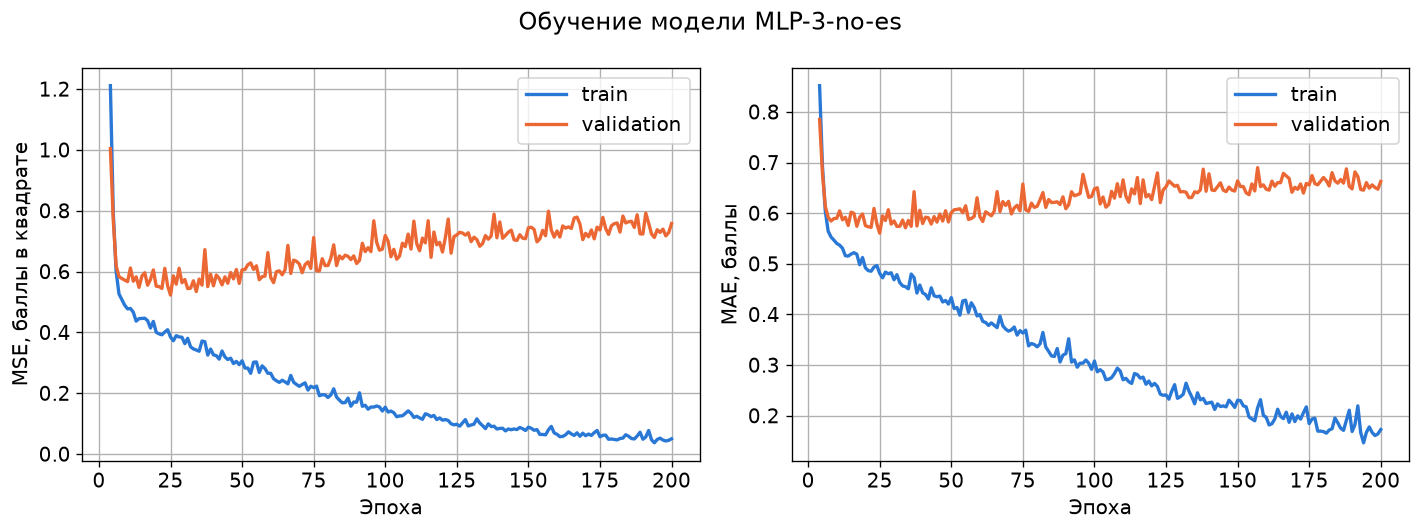

MLP-3-no-es-dropout: эпох 200, лучшая 200, 207 с, {'MSE': 0.5385, 'MAE': 0.5715, 'R2': 0.3163}


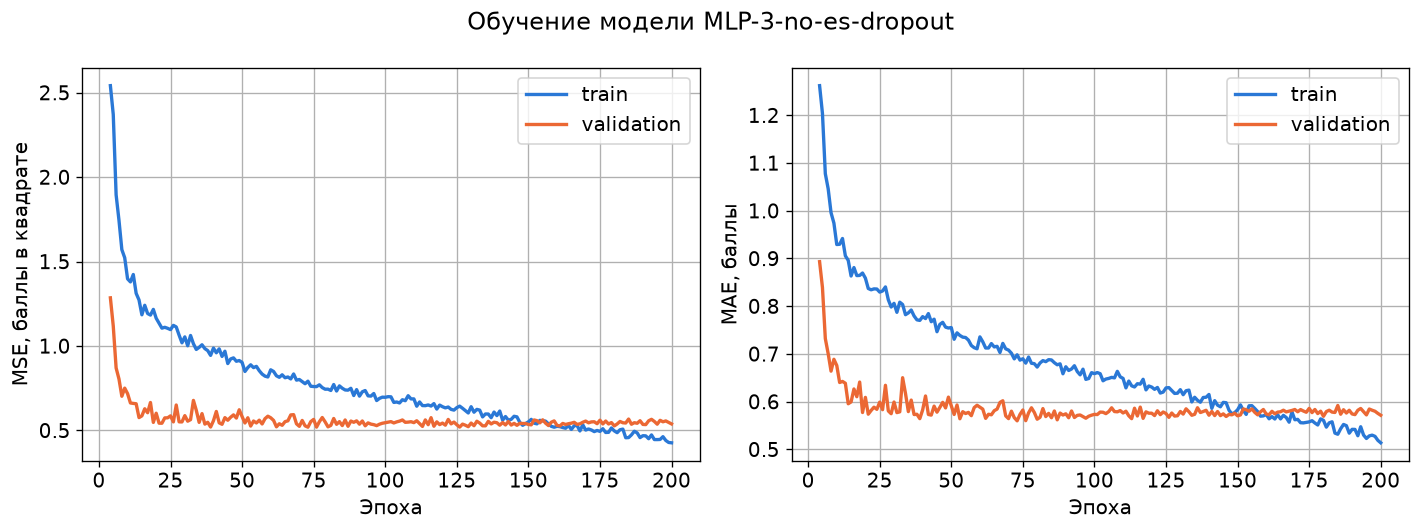

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-3,256-128-64,relu,adam,0.001,64,0.0,0.0,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
1,MLP-3-no-es,256-128-64,relu,adam,0.001,64,0.0,0.0,44289,200,200,202.2,0.0586,0.7575,0.6625,0.0382
2,MLP-3-no-es-dropout,256-128-64,relu,adam,0.001,64,0.3,0.0,44289,200,200,206.8,0.2665,0.5385,0.5715,0.3163


In [21]:
# Большая сеть без ранней остановки: показываем, как выглядит переобучение на этих данных
overfit_config = dict(model_configs["MLP-3"])
run_experiment("MLP-3-no-es", **overfit_config, max_epochs=200, use_early_stopping=False)
plot_history("MLP-3-no-es", "regression-overfit-history.png")

# Та же сеть с Dropout и тоже без ранней остановки
run_experiment("MLP-3-no-es-dropout", **{**overfit_config, "dropout_rate": 0.3}, max_epochs=200,
               use_early_stopping=False)
plot_history("MLP-3-no-es-dropout", "regression-dropout-history.png")
experiments_table(["MLP-3", "MLP-3-no-es", "MLP-3-no-es-dropout"])

In [22]:
# Те же приемы на текущей лучшей модели, с обычными условиями обучения
dropout_name = f"{current_name}-dropout"
l2_name = f"{current_name}-l2"
run_experiment(dropout_name, **{**current_config, "dropout_rate": 0.3})
run_experiment(l2_name, **{**current_config, "l2_factor": 0.0001})

regularization_names = [current_name, dropout_name, l2_name]
current_name = select_simplest_best(regularization_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(regularization_names)

MLP-3-dropout: эпох 59, лучшая 39, 50 с, {'MSE': 0.52, 'MAE': 0.5644, 'R2': 0.3397}


MLP-3-l2: эпох 45, лучшая 25, 41 с, {'MSE': 0.5177, 'MAE': 0.5587, 'R2': 0.3427}
Оставляем: MLP-3-l2


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-3,256-128-64,relu,adam,0.001,64,0.0,0.0000,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
1,MLP-3-dropout,256-128-64,relu,adam,0.001,64,0.3,0.0000,44289,59,39,49.8,0.4433,0.5200,0.5644,0.3397
2,MLP-3-l2,256-128-64,relu,adam,0.001,64,0.0,0.0001,44289,45,25,40.9,0.3512,0.5177,0.5587,0.3427


**Результат:** на этих данных переобучение самое сильное из трех задач. У MLP-3-no-es к 200-й эпохе train MSE 0,0586, а validation MSE 0,7575, R2 упал до 0,0382, сеть почти заучила обучающую часть. Dropout 0,3 это исправил: train MSE 0,2665, validation MSE 0,5385, R2 0,3163. Значит, без ранней остановки Dropout здесь нужен.

На текущей лучшей модели с ранней остановкой: Dropout дал MSE 0,5200, L2 дала 0,5177 против 0,5225 без регуляризации. Обе улучшают результат, L2 лучше на 0,0023, это больше порога шума. Train MSE у L2 почти не изменился (0,3512). Оставляем MLP-3-l2. Функция потерь этой модели содержит штраф L2, поэтому графики и метрики показывают MSE отдельно от loss.

### 8. Анализ ошибок на validation

Смотрим, где модель ошибается: строим прогноз против истинной оценки и среднюю ошибку для каждой оценки качества. Так видно, почему R2 ограничен.

Итоговая модель: MLP-3-l2


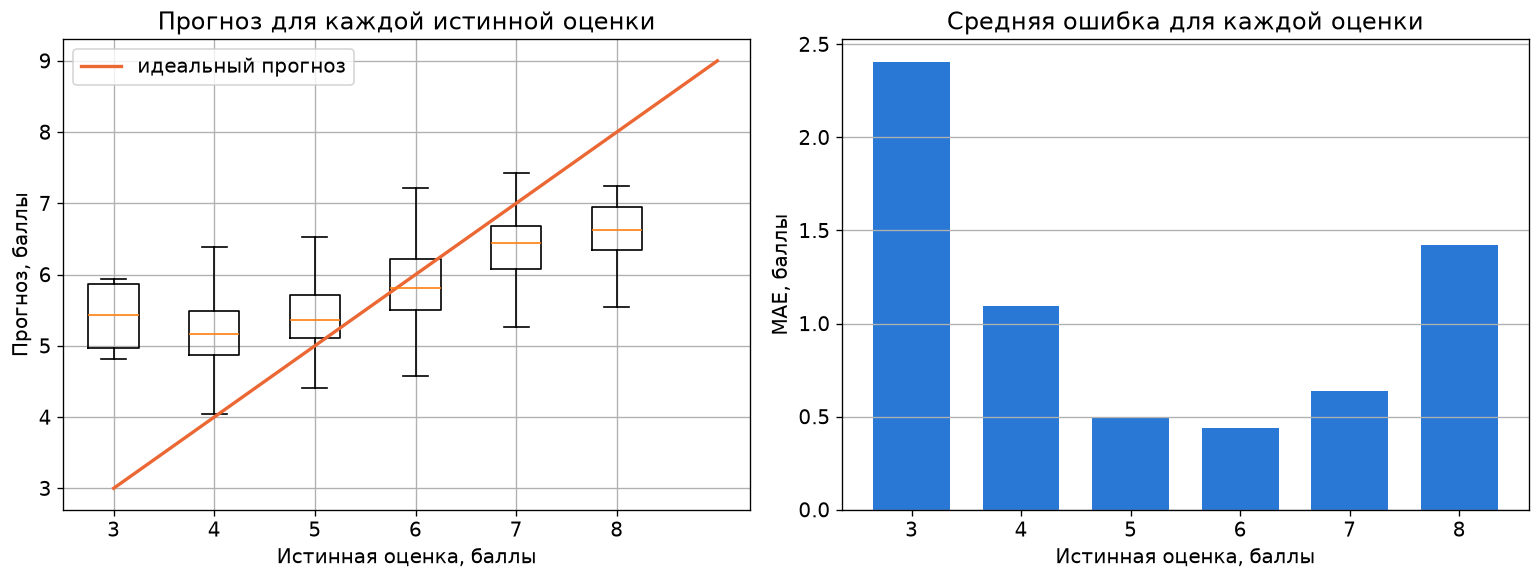

,Оценка,Вин,Средний прогноз,MAE
0,3,4,5.4056,2.4056
1,4,27,5.0931,1.0931
2,5,191,5.4210,0.4943
3,6,257,5.8688,0.4397
4,7,100,6.3796,0.6401
5,8,15,6.5774,1.4226


In [23]:
# Модели без ранней остановки нужны были только для показа переобучения
selectable_names = [row["Модель"] for row in experiment_rows if "no-es" not in row["Модель"]]
final_name = select_simplest_best(selectable_names)
final_model = trained_models[final_name]
print("Итоговая модель:", final_name)

val_predictions = final_model.predict(X_val, batch_size=4096, verbose=0).ravel()

figure, axes = plt.subplots(1, 2, figsize=(13, 5))

# Разброс точек по вертикали показывает, что оценка часто одна, а свойства вин разные
quality_values = np.sort(np.unique(y_val))
predictions_by_quality = [val_predictions[y_val == value] for value in quality_values]
axes[0].boxplot(predictions_by_quality, positions=quality_values, widths=0.5, showfliers=False)
axes[0].plot([3, 9], [3, 9], color=VAL_COLOR, linewidth=2, label="идеальный прогноз")
axes[0].set_xticks(quality_values, labels=quality_values.astype(int))
axes[0].set_xlabel("Истинная оценка, баллы")
axes[0].set_ylabel("Прогноз, баллы")
axes[0].set_title("Прогноз для каждой истинной оценки")
axes[0].legend()

# Средняя ошибка по оценкам: редкие крайние оценки предсказываются хуже всего
error_rows = []
for value in quality_values:
    mask = y_val == value
    error_rows.append({"Оценка": int(value), "Вин": int(mask.sum()),
                       "Средний прогноз": round(float(val_predictions[mask].mean()), 4),
                       "MAE": round(float(np.abs(val_predictions[mask] - y_val[mask]).mean()), 4)})
error_table = pd.DataFrame(error_rows)
error_table.to_csv(RESULTS_DIR / "regression-errors-by-quality.csv", index=False, encoding="utf-8")
axes[1].bar(error_table["Оценка"].astype(str), error_table["MAE"], color=TRAIN_COLOR, width=0.7)
axes[1].set_xlabel("Истинная оценка, баллы")
axes[1].set_ylabel("MAE, баллы")
axes[1].set_title("Средняя ошибка для каждой оценки")
axes[1].grid(axis="x", visible=False)

figure.tight_layout()
figure.savefig(FIGURES_DIR / "regression-errors.png")
plt.show()
error_table

**Результат:** итоговая модель MLP-3-l2 средние оценки предсказывает хорошо: MAE 0,49 для оценки 5 и 0,44 для оценки 6. Крайние оценки предсказывает плохо: для оценки 3 средний прогноз 5,41 (MAE 2,41), для оценки 8 средний прогноз 6,58 (MAE 1,42). Прогноз тянется к середине, потому что вин с крайними оценками мало (4 и 15 на validation), а MSE выгоднее снижать на массовых оценках. Кроме того, оценки целые, а прогноз непрерывный, поэтому даже правильное направление дает ошибку. Отсюда низкий R2.

### 9. Сводная таблица экспериментов

Все исследованные модели с параметрами и метриками на validation. Таблица сохраняется в `results/regression-experiments.csv`.

In [24]:
all_experiments = experiments_table()
all_experiments.to_csv(RESULTS_DIR / "regression-experiments.csv", index=False, encoding="utf-8")

# Истории обучения трех основных архитектур и итоговой модели сохраняем для отчета
for file_suffix, model_name in [("mlp-1", "MLP-1"), ("mlp-2", "MLP-2"), ("mlp-3", "MLP-3"), ("best", final_name)]:
    pd.DataFrame(trained_histories[model_name]).round(4).to_csv(
        RESULTS_DIR / f"regression-history-{file_suffix}.csv", index_label="epoch", encoding="utf-8")

pd.set_option("display.max_columns", None, "display.width", 250)
all_experiments

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Параметров,Эпох,Лучшая эпоха,Секунд,train MSE,MSE,MAE,R2
0,MLP-1,16,relu,adam,0.0010,64,0.0,0.0000,209,199,179,125.5,0.4570,0.5497,0.5884,0.3020
1,MLP-2,64-32,relu,adam,0.0010,64,0.0,0.0000,2881,83,63,51.8,0.4070,0.5315,0.5628,0.3252
2,MLP-3,256-128-64,relu,adam,0.0010,64,0.0,0.0000,44289,45,25,30.6,0.3494,0.5225,0.5604,0.3366
3,MLP-3-tanh,256-128-64,tanh,adam,0.0010,64,0.0,0.0000,44289,64,44,43.7,0.4133,0.5300,0.5707,0.3271
4,MLP-3-rmsprop,256-128-64,relu,rmsprop,0.0010,64,0.0,0.0000,44289,59,39,44.4,0.2920,0.5612,0.5871,0.2875
5,MLP-3-sgd,256-128-64,relu,sgd,0.0100,64,0.0,0.0000,44289,30,10,27.4,0.4197,0.5354,0.5767,0.3203
6,MLP-3-lr0.01,256-128-64,relu,adam,0.0100,64,0.0,0.0000,44289,52,32,39.6,0.3579,0.5363,0.5743,0.3191
7,MLP-3-lr0.0001,256-128-64,relu,adam,0.0001,64,0.0,0.0000,44289,117,97,85.2,0.3472,0.5297,0.5701,0.3274
8,MLP-3-batch32,256-128-64,relu,adam,0.0010,32,0.0,0.0000,44289,36,16,52.0,0.3903,0.5357,0.5703,0.3199
9,MLP-3-batch256,256-128-64,relu,adam,0.0010,256,0.0,0.0000,44289,68,48,27.4,0.3740,0.5241,0.5621,0.3345


## Итоговая оценка на тестовой выборке

Выбор модели закончен, все решения приняты по validation. Теперь один раз считаем метрики всех моделей на test как отчет. После этой таблицы модели не меняются.

In [25]:
test_rows = []
for model_name, model in trained_models.items():
    test_predictions = model.predict(X_test, batch_size=4096, verbose=0).ravel()
    note = "итоговая модель" if model_name == final_name else ""
    test_rows.append({"Модель": model_name, **evaluate_regression(y_test, test_predictions), "Примечание": note})
test_rows.append({"Модель": "Dummy", **evaluate_regression(y_test, dummy_model.predict(X_test)),
                  "Примечание": "базовая модель"})

test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(RESULTS_DIR / "regression-metrics.csv", index=False, encoding="utf-8")
test_metrics

,Модель,MSE,MAE,R2,Примечание
0,MLP-1,0.5620,0.5858,0.2842,
1,MLP-2,0.5545,0.5833,0.2937,
2,MLP-3,0.5671,0.5833,0.2776,
3,MLP-3-tanh,0.5291,0.5676,0.3260,
4,MLP-3-rmsprop,0.5447,0.5734,0.3062,
5,MLP-3-sgd,0.5443,0.5732,0.3067,
6,MLP-3-lr0.01,0.5608,0.5850,0.2857,
7,MLP-3-lr0.0001,0.5523,0.5815,0.2965,
8,MLP-3-batch32,0.6003,0.5926,0.2353,
9,MLP-3-batch256,0.5644,0.5841,0.2810,


Кривые итоговой модели с линией итогового значения на test и сравнение прогноза с истинной оценкой.

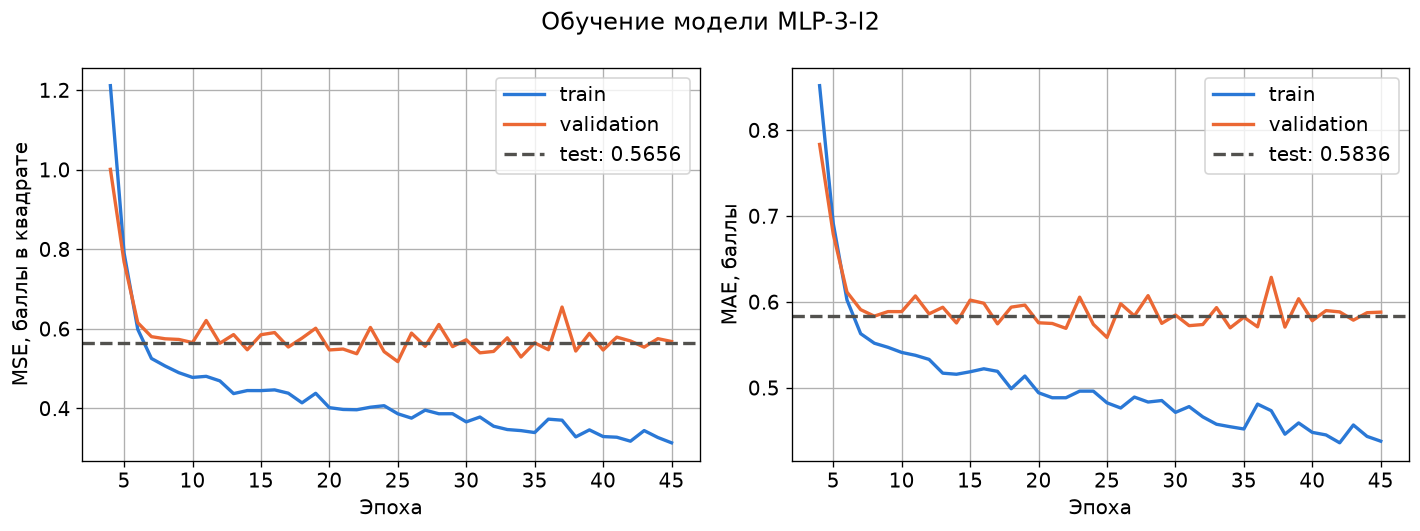

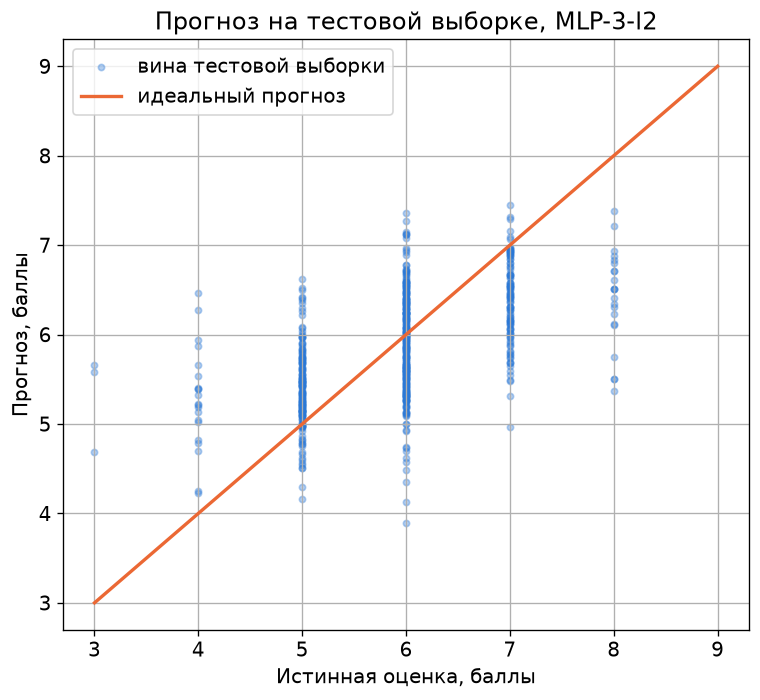

In [26]:
test_loss, test_mse, test_mae = final_model.evaluate(X_test, y_test, batch_size=4096, verbose=0)
plot_history(final_name, "regression-best-history.png", test_values={"mse": test_mse, "mae": test_mae})

final_test_predictions = final_model.predict(X_test, batch_size=4096, verbose=0).ravel()
figure, axis = plt.subplots(figsize=(6.5, 6))
axis.scatter(y_test, final_test_predictions, s=14, alpha=0.35, color=TRAIN_COLOR, label="вина тестовой выборки")
axis.plot([3, 9], [3, 9], color=VAL_COLOR, linewidth=2, label="идеальный прогноз")
axis.set_xlabel("Истинная оценка, баллы")
axis.set_ylabel("Прогноз, баллы")
axis.set_title(f"Прогноз на тестовой выборке, {final_name}")
axis.legend(loc="upper left")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "regression-predictions.png")
plt.show()

In [27]:
# Сохраняем основные архитектуры и итоговую модель. Лабораторная работа 5 загружает
# regression-best.keras и regression-preprocessor.joblib, а не обучает модель заново
for model_name in ["MLP-1", "MLP-2", "MLP-3"]:
    trained_models[model_name].save(MODELS_DIR / f"regression-{model_name.lower()}.keras")
final_model.save(MODELS_DIR / "regression-best.keras")

final_info = {"model": final_name, "config": model_configs[final_name]}
with open(MODELS_DIR / "regression-best-info.json", "w", encoding="utf-8") as info_file:
    json.dump(final_info, info_file, ensure_ascii=False, indent=2)
print(json.dumps(final_info, ensure_ascii=False, indent=2))

{
  "model": "MLP-3-l2",
  "config": {
    "hidden_units": [
      256,
      128,
      64
    ],
    "activation": "relu",
    "optimizer_name": "adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "dropout_rate": 0.0,
    "l2_factor": 0.0001
  }
}


**Результат:** на test итоговая модель MLP-3-l2 дала MSE 0,5656, MAE 0,5836, R2 0,2796. `Dummy` на test: MSE 0,7860, MAE 0,6719, R2 -0,0012. Модель снижает MSE на 28% относительно `Dummy`, а средняя ошибка составляет 0,58 балла.

На test результат хуже, чем на validation (R2 0,2796 против 0,3427). Причина в том, что лучшая из 12 моделей с ранней остановкой выбрана по маленькой выборке из 594 вин: она частично подстроена под эту выборку. Значение на test честнее, его и считаем итоговым.

В таблице видно, что R2 моделей с ранней остановкой на test лежит от 0,2353 до 0,3260, причем порядок моделей не совпадает с порядком на validation. Например, MLP-3-tanh на test лучше итоговой модели (R2 0,3260). Это показывает, что различия лежат в пределах шума, но выбор сделан по validation и после этой таблицы не меняется.

MLP-3-no-es случайно совпала с `Dummy` по MSE и R2 (0,7860 и -0,0012), но это разные модели: их MAE различаются (0,6850 и 0,6719). Совпадение наглядно показывает, что переобученная сеть не лучше прогноза средним.

## Вывод

Построен регрессор качества белого вина. Лучшая модель - MLP-3-l2: скрытые слои 256, 128 и 64 с ReLU, линейный выход, Adam, скорость обучения 0,001, размер пакета 64, L2 0,0001.

| Метрика на test | Итоговая модель | Dummy | Ориентир |
|---|---|---|---|
| MSE | 0,5656 | 0,7860 | чем меньше, тем лучше |
| MAE | 0,5836 | 0,6719 | чем меньше, тем лучше |
| R2 | 0,2796 | -0,0012 | 0,80 |

**Сравнение с базовой моделью.** Модель лучше `Dummy`: MSE ниже на 28%, но средняя ошибка снизилась умеренно, с 0,67 до 0,58 балла. Модель объясняет около 28% дисперсии оценки.

**Выбор архитектуры.** На validation более сложная сеть дала меньшую ошибку, поэтому выбрана MLP-3 с L2. Но различия малы, а на test порядок моделей другой. Значит, на таком объеме данных выбор архитектуры влияет на результат меньше, чем случайность разбиения.

**Переобучение.** Сеть сильнее всего переобучается именно здесь: параметров намного больше, чем записей. Без ранней остановки R2 на validation падает до 0,0382. Защиту дают ранняя остановка и L2. Dropout также исправляет переобучение, но L2 оказалась лучше на validation. Разрыв между train и validation у итоговой модели остается.

**Почему R2 намного ниже ориентира 0,80.**

1. Оценка субъективна: это медиана оценок экспертов, а часть различий во вкусе не отражена в 11 физико-химических показателях. Нет данных о сорте винограда и марке.
2. 937 дубликатов удалены: одинаковые записи в train и test завысили бы метрики, поэтому полученное значение R2 честное, хотя и низкое.
3. Данных мало (2772 записи в train), а крайних оценок почти нет, поэтому прогноз тянется к середине.
4. Цель целочисленная, а значит прогноз непрерывной величины всегда имеет ошибку округления.

**Ограничения и возможные улучшения.** Различия моделей близки к шуму, поэтому для надежного выбора лучше использовать кросс-валидацию вместо одной валидационной выборки. Помогли бы также новые признаки (сорт, регион) и больше вин с крайними оценками.